# 04 - Bayesian price effect, and why it is fragile

**Decision question:** if monthly charges rise 10%, how much does churn change -
and how sure can we be?

A Bayesian logistic regression (PyMC) gives a full posterior for the price effect,
so the answer is a distribution rather than a point and a p-value. That precision
is real, but it is precision *conditional on the adjustment set*. This notebook
adds four things the first version lacked: a causal diagram, the collinearity that
drives the sign flip, a posterior predictive check, and a sensitivity analysis for
unmeasured confounding.

**The finding stands:** two defensible adjustment sets disagree on the sign. That
is not a bug to be tuned away. It is the reason observational data cannot set a
price, and the reason notebook 05 designs an experiment.

In [1]:
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
import pymc as pm
from pathlib import Path
from scipy.special import expit

from telco_churn.data import load_clean

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(42)

df = load_clean()
y = df.Churn.to_numpy()
mu, sd = df.MonthlyCharges.mean(), df.MonthlyCharges.std()
price_z = ((df.MonthlyCharges - mu) / sd).to_numpy()
up = ((df.MonthlyCharges * 1.10 - mu) / sd).to_numpy()

contract = pd.get_dummies(df.Contract).reindex(
    columns=["One year", "Two year"], fill_value=0).astype(float).to_numpy()
internet = pd.get_dummies(df.InternetService).reindex(
    columns=["Fiber optic", "No"], fill_value=0).astype(float).to_numpy()

print(f"{len(df):,} customers, {y.mean():.1%} churned; price mean £{mu:.2f}, sd £{sd:.2f}")

7,043 customers, 26.5% churned; price mean £64.76, sd £30.09


## The causal picture

```
             contract ─────────────┐
                 │                 │
                 ▼                 ▼
   service type (fibre/DSL) ───► price ───► churn
                 │                 ▲          ▲
                 └─────────────────┘          │
                                    unmeasured: income,
                                    competitors, promotions
```

Price is not assigned at random. It is set by the company *because of* the service
bundle, and customers choose bundles partly on price. Conditioning on service type
closes one back-door path and opens a different view of the same data. That is why
the answer moves.

## Model A and Model B

Identical likelihood, identical priors, one difference: Model B also controls for
internet service type. Both are reasonable choices, which is exactly the problem.

In [2]:
def fit(extra, price_sd: float = 1.0, draws: int = 500, tune: int = 500, seed: int = 42):
    # cores=1 keeps sampling serial; it is slower but reliable inside notebooks
    # and on CI runners, and 4 chains still give the diagnostics we need.
    with pm.Model() as model:
        a = pm.Normal("intercept", 0, 1.5)
        b_price = pm.Normal("b_price", 0, price_sd)
        b_other = pm.Normal("b_other", 0, 1, shape=extra.shape[1])
        pm.Bernoulli("churn", logit_p=a + b_price * price_z + pm.math.dot(extra, b_other),
                     observed=y)
        idata = pm.sample(draws=draws, tune=tune, chains=4, cores=1,
                          random_seed=seed, progressbar=False)
    return idata, model


def price_effect(idata, extra, pct: float = 0.10) -> np.ndarray:
    # Posterior change in average churn rate (percentage points) if every price
    # rises by pct. Vectorised over draws and customers.
    post = az.extract(idata)
    a = post["intercept"].values
    bp = post["b_price"].values
    bo = post["b_other"].values
    if bo.shape[0] != a.shape[0]:      # arviz keeps the parameter dim first
        bo = bo.T
    base = a[:, None] + bo @ extra.T
    _mu, _sd = df.MonthlyCharges.mean(), df.MonthlyCharges.std()
    target = ((df.MonthlyCharges * (1 + pct) - _mu) / _sd).to_numpy()
    p_now = expit(base + bp[:, None] * price_z)
    p_up = expit(base + bp[:, None] * target)
    return (p_up.mean(axis=1) - p_now.mean(axis=1)) * 100


extra_A, extra_B = contract, np.hstack([contract, internet])
idata_A, model_A = fit(extra_A)
idata_B, model_B = fit(extra_B)

for name, idata in [("A (contract)", idata_A), ("B (contract + internet)", idata_B)]:
    s = az.summary(idata)
    print(f"Model {name}: max R-hat {s.r_hat.max():.3f}, min ESS {int(s.ess_bulk.min())}, "
          f"divergences {int(idata.sample_stats['diverging'].sum())}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, b_price, b_other]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 21 seconds.


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, b_price, b_other]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 49 seconds.


Model A (contract): max R-hat 1.007, min ESS 1627, divergences 0
Model B (contract + internet): max R-hat 1.004, min ESS 975, divergences 0


## Why the sign flips: price is bundled with service

Before reading the posterior, look at the raw association. Price and fibre are
close to the same variable, and fibre customers churn more. Any model that holds
fibre fixed is estimating a price effect from the *within-service-type* variation
that remains - a much thinner and more selected margin.

In [3]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

design = pd.DataFrame({
    "price (z)": price_z,
    "one-year contract": contract[:, 0],
    "two-year contract": contract[:, 1],
    "fibre": internet[:, 0],
    "no internet": internet[:, 1],
    "churn": y,
})
print("Correlation with price:")
print(design.corr()["price (z)"].drop("price (z)").round(3).to_string())
print(f"\nShare of fibre customers churning: {y[internet[:, 0] == 1].mean():.1%}")
dsl = (internet[:, 0] == 0) & (internet[:, 1] == 0)
print(f"Share of DSL customers churning:  {y[dsl].mean():.1%}")

for label, cols in [("contract only", ["price (z)", "one-year contract", "two-year contract"]),
                    ("contract + internet", ["price (z)", "one-year contract",
                                             "two-year contract", "fibre", "no internet"])]:
    X = design[cols].to_numpy()
    vifs = {c: variance_inflation_factor(X, i) for i, c in enumerate(cols)}
    print(f"\nVIF ({label}): " + ", ".join(f"{c}={v:.1f}" for c, v in vifs.items()))

Correlation with price:
one-year contract    0.005
two-year contract   -0.075
fibre                0.787
no internet         -0.764
churn                0.193

Share of fibre customers churning: 41.9%
Share of DSL customers churning:  19.0%

VIF (contract only): price (z)=1.0, one-year contract=1.0, two-year contract=1.0

VIF (contract + internet): price (z)=5.4, one-year contract=1.2, two-year contract=1.4, fibre=2.8, no internet=4.2


The variance inflation factor for price roughly doubles once internet service is
added. That is the mechanism behind the sign flip, in one number. It also means
the posterior intervals are tight around two different answers, not wide around
one: the MCMC is working correctly and the *identification* is not.

Model A: contract only             +10% price -> +2.04 pp churn (94% interval +1.80 to +2.28); P(change > 0) = 100%
Model B: contract + internet       +10% price -> -1.23 pp churn (94% interval -1.73 to -0.68); P(change > 0) = 0%


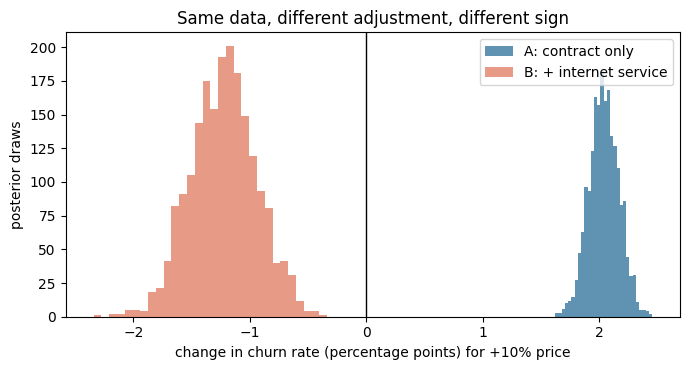

,mean pp,2.5%,97.5%,P(>0)
model,,,,
A: contract only,2.039,1.788,2.291,1.0
B: contract + internet,-1.225,-1.756,-0.670,0.0


In [4]:
dA, dB = price_effect(idata_A, extra_A), price_effect(idata_B, extra_B)
summary = []
for name, d in [("A: contract only", dA), ("B: contract + internet", dB)]:
    lo, hi = np.percentile(d, [3, 97])
    summary.append({"model": name, "mean pp": d.mean(), "2.5%": np.percentile(d, 2.5),
                    "97.5%": np.percentile(d, 97.5), "P(>0)": (d > 0).mean()})
    print(f"Model {name:28s} +10% price -> {d.mean():+.2f} pp churn "
          f"(94% interval {lo:+.2f} to {hi:+.2f}); P(change > 0) = {(d > 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(dA, bins=30, alpha=0.75, label="A: contract only", color="#2a6f97")
ax.hist(dB, bins=30, alpha=0.75, label="B: + internet service", color="#e07a5f")
ax.axvline(0, color="k", lw=1)
ax.legend()
ax.set_xlabel("change in churn rate (percentage points) for +10% price")
ax.set_ylabel("posterior draws")
ax.set_title("Same data, different adjustment, different sign")
plt.tight_layout()
plt.savefig(FIG / "04_price_effect_posterior.png", dpi=140)
plt.show()
pd.DataFrame(summary).set_index("model").round(3)

## Posterior predictive check

A model can fit the coefficient table and still fail to reproduce the outcome it
is meant to describe. Simulating churn from the posterior and comparing the
simulated churn rate with the observed rate is the minimum check.

Sampling: [churn]


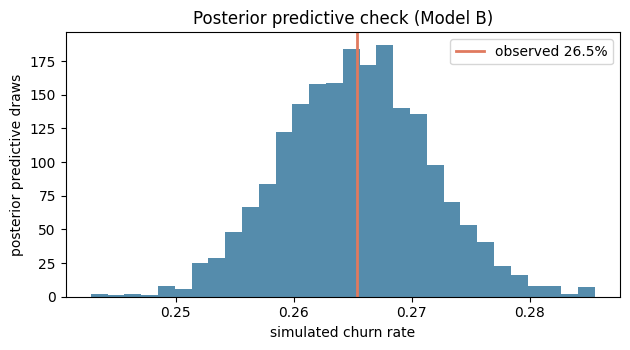

Observed churn rate: 0.265
Simulated 95% interval: [0.253 0.278]
Posterior predictive p-value (simulated >= observed): 0.50


In [5]:
with model_B:
    pm.sample_posterior_predictive(idata_B, extend_inferencedata=True,
                                   random_seed=42, progressbar=False)

ppc = idata_B.posterior_predictive["churn"].values.reshape(-1, len(y))
sim_rates = ppc.mean(axis=1)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.hist(sim_rates, bins=30, color="#2a6f97", alpha=0.8)
ax.axvline(y.mean(), color="#e07a5f", lw=2, label=f"observed {y.mean():.1%}")
ax.set_xlabel("simulated churn rate")
ax.set_ylabel("posterior predictive draws")
ax.set_title("Posterior predictive check (Model B)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "04_ppc.png", dpi=140)
plt.show()

print(f"Observed churn rate: {y.mean():.3f}")
print(f"Simulated 95% interval: {np.percentile(sim_rates, [2.5, 97.5]).round(3)}")
print(f"Posterior predictive p-value (simulated >= observed): {(sim_rates >= y.mean()).mean():.2f}")

## Prior sensitivity

The priors are deliberately weak, but "weak" is not the same as "irrelevant".
Refit Model B with a tighter and a wider prior on the price coefficient. If the
conclusion moves, the data are not speaking loudly enough.

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, b_price, b_other]


Sampling 4 chains for 400 tune and 400 draw iterations (1_600 + 1_600 draws total) took 40 seconds.


Initializing NUTS using jitter+adapt_diag...


...

prior sd 1.0: b_price posterior mean -0.351


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, b_price, b_other]


Sampling 4 chains for 400 tune and 400 draw iterations (1_600 + 1_600 draws total) took 39 seconds.


prior sd 2.0: b_price posterior mean -0.352
 prior sd  posterior mean (pp)  95% low  95% high
      0.5               -1.195   -1.764    -0.607
      1.0               -1.238   -1.774    -0.690
      2.0               -1.240   -1.793    -0.683


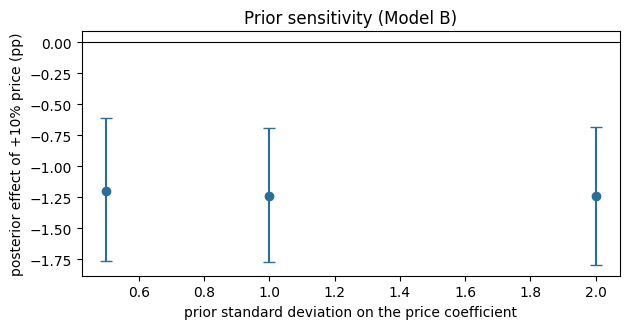

In [6]:
rows = []
for prior_sd in (0.5, 1.0, 2.0):
    idata, _ = fit(extra_B, price_sd=prior_sd, draws=400, tune=400)
    d = price_effect(idata, extra_B)
    print(f"prior sd {prior_sd}: b_price posterior mean "
          f"{float(np.mean(az.extract(idata)['b_price'].values)):+.3f}")
    rows.append({"prior sd": prior_sd, "posterior mean (pp)": d.mean(),
                 "95% low": np.percentile(d, 2.5), "95% high": np.percentile(d, 97.5)})
prior_sensitivity = pd.DataFrame(rows)
print(prior_sensitivity.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.errorbar(prior_sensitivity["prior sd"], prior_sensitivity["posterior mean (pp)"],
            yerr=[prior_sensitivity["posterior mean (pp)"] - prior_sensitivity["95% low"],
                  prior_sensitivity["95% high"] - prior_sensitivity["posterior mean (pp)"]],
            fmt="o", capsize=4, color="#2a6f97")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("prior standard deviation on the price coefficient")
ax.set_ylabel("posterior effect of +10% price (pp)")
ax.set_title("Prior sensitivity (Model B)")
plt.tight_layout()
plt.savefig(FIG / "04_prior_sensitivity.png", dpi=140)
plt.show()

## How much confounding would overturn this?

The estimates are near the null, which cuts both ways: they are easy to dismiss.
One way to quantify that is the E-value: the minimum strength of association an
unmeasured confounder would need with both price and churn to explain away the
observed risk ratio. Values near 1 mean "almost any confounder could do it".

In [7]:
def evalue_rr(rr: float) -> float:
    rr = rr if rr >= 1 else 1 / rr
    return rr + np.sqrt(rr * (rr - 1))


rows = []
for name, d in [("A: contract only", dA), ("B: contract + internet", dB)]:
    base = y.mean()
    rr = (base + d.mean() / 100) / base
    rows.append({"model": name, "risk ratio for +10%": rr, "E-value": evalue_rr(rr)})
evalues = pd.DataFrame(rows).set_index("model")
print(evalues.round(3).to_string())
print("\nRead: an unmeasured factor associated with both price and churn by about "
      "this factor could wipe out the entire association.")

                        risk ratio for +10%  E-value
model                                               
A: contract only                      1.077    1.364
B: contract + internet                0.954    1.274

Read: an unmeasured factor associated with both price and churn by about this factor could wipe out the entire association.


## What this tells a commercial leader

- Both models converged and both give tight intervals, yet they disagree on
  direction. A narrow interval measures sampling noise, not identification.
- The mechanism is visible in the data: price and fibre are close to the same
  variable, and the price VIF roughly doubles when internet service is controlled.
- The estimates are small enough that a modest unmeasured confounder (an E-value
  near 1) could explain them away entirely.
- **Recommendation:** do not set prices from this analysis. Use it to choose which
  segments to test and how large an effect would matter, then run the price or
  offer experiment designed in notebook 05.

## Limitations

- Observational data with unmeasured confounders: income, competitors, promotions,
  installation quality.
- Only two adjustment sets are compared. A full DAG-based adjustment set would
  need variables this dataset does not contain.
- The +10% counterfactual is applied to every customer, which extrapolates beyond
  observed price variation. A within-bundle price test is the defensible version.
- Priors are weak and simple; the sensitivity table shows the conclusion is not
  driven by them, but a formal prior-elicitation exercise is out of scope.